# Spatial expression denoising with ResolVI (`ov.vi.RESOLVI` / `ov.space.resolvi`)

ResolVI (Ergen & Yosef, *Nature Methods* 2026; preprint [bioRxiv 2025](https://doi.org/10.1101/2025.01.20.634005)) models every cell's observed transcript counts in imaging-based spatial data (Xenium / MERFISH / CosMx) as a mixture of three sources:

* **true** — the cell's own, denoised expression, decoded from a latent `z`;
* **diffusion** — transcripts that leaked in from spatial neighbours (segmentation error, optical cross-talk);
* **background** — ambient signal shared by every cell on the slide.

Segmentation in imaging-based spatial platforms is imperfect, so a cell's raw counts are a mix of its own transcripts and its neighbours'. A marker that is genuinely specific at the mRNA level (a T-cell receptor subunit, a B-cell surface marker) can look diffuse once counted per "cell", simply because nearby cells' transcripts spill into the wrong segmentation mask. ResolVI is trained, per cell, to undo this — splitting counts back into the three channels above and giving a corrected, denoised expression estimate.

This notebook uses `ov.vi`'s own PyTorch implementation of `scvi.external.RESOLVI` (scvi-tools 1.5.2) — **no scvi-tools / pyro / jax dependency**. On the validation benchmark (`benchmarks/vi/results_resolvi.md` in the omicverse repo, same dataset as below), its clustering purity (ARI/NMI) and marker-specificity AUROC are statistically indistinguishable from (slightly better than) the pyro reference, and training is 1.5-8x faster.

We reproduce the same real dataset used for that validation: the public **10x Genomics Xenium FFPE Human Breast Cancer, Replicate 1** sample (Janesick *et al.*, *Nature Communications* 2023), with 10x's own supervised cell-type calls as an independent check. We show: denoised vs. raw marker expression on the tissue for markers that leak across cell boundaries, the per-cell true/diffusion/background mixture on the tissue, marker specificity before/after denoising, latent-space clustering, and the semi-supervised label-transfer variant.

## 1. Setup

In [1]:
import omicverse as ov
import anndata as ad
import numpy as np
import pandas as pd
ov.style()

🔬 Starting plot initialization...
🧬 Detecting GPU devices…


✅ NVIDIA CUDA GPUs detected: 2
    • [CUDA 0] NVIDIA H100 80GB HBM3
      Memory: 79.1 GB | Compute: 9.0
    • [CUDA 1] NVIDIA H100 80GB HBM3
      Memory: 79.1 GB | Compute: 9.0

   ____            _     _    __                  
  / __ \____ ___  (_)___| |  / /__  _____________ 
 / / / / __ `__ \/ / ___/ | / / _ \/ ___/ ___/ _ \ 
/ /_/ / / / / / / / /__ | |/ /  __/ /  (__  )  __/ 
\____/_/ /_/ /_/_/\___/ |___/\___/_/  /____/\___/                                              

🔖 Version: 2.4.2   📚 Tutorials: https://omicverse.readthedocs.io/
✅ plot_set complete.



## 2. Data: 10x Xenium FFPE Human Breast Cancer, Replicate 1

A 313-gene breast-cancer panel on a single FFPE section, ~168,000 segmented cells (Janesick *et al.* 2023). We download the two files a Xenium analysis needs directly from 10x's own CDN, plus 10x's own **supervised** cell-type calls for this sample (a supplementary file of the paper, also mirrored at GEO [GSE243275](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE243275)) — used only as an independent check of the unsupervised model and as labels for the semi-supervised section, never as training input for the unsupervised run.

In [2]:
BASE = 'https://cf.10xgenomics.com/samples/xenium/1.0.1/Xenium_FFPE_Human_Breast_Cancer_Rep1'
DATA_DIR = '/scratch/users/steorra/tmp/vi_tut2/resolvi/data'
ov.datasets.download_data_requests(f'{BASE}/Xenium_FFPE_Human_Breast_Cancer_Rep1_cell_feature_matrix.h5', file_path='cell_feature_matrix.h5', dir=DATA_DIR)
ov.datasets.download_data_requests(f'{BASE}/Xenium_FFPE_Human_Breast_Cancer_Rep1_cells.csv.gz', file_path='cells.csv.gz', dir=DATA_DIR)
ov.datasets.download_data_requests('https://cdn.10xgenomics.com/raw/upload/v1695234604/Xenium%20Preview%20Data/Cell_Barcode_Type_Matrices.xlsx', dir=DATA_DIR)

⚠️ File /scratch/users/steorra/tmp/vi_tut2/resolvi/data/cell_feature_matrix.h5 already exists
⚠️ File /scratch/users/steorra/tmp/vi_tut2/resolvi/data/cells.csv.gz already exists
⚠️ File /scratch/users/steorra/tmp/vi_tut2/resolvi/data/Cell_Barcode_Type_Matrices.xlsx already exists


'/scratch/users/steorra/tmp/vi_tut2/resolvi/data/Cell_Barcode_Type_Matrices.xlsx'

In [3]:
adata = ov.io.read_xenium(DATA_DIR, load_image=False, load_boundaries=False)
adata

[Xenium] Reading Xenium data from: /scratch/users/steorra/tmp/vi_tut2/resolvi/data


[Xenium] Done (n_obs=167780, n_vars=313, library_id=data)


AnnData object with n_obs × n_vars = 167780 × 313
    obs: 'transcript_counts', 'control_probe_counts', 'control_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area'
    var: 'gene_ids', 'feature_types', 'genome'
    uns: 'spatial', 'omicverse_io'
    obsm: 'spatial'
    layers: None (.X)

10x's supervised calls are merged into `obs['cell_type']` and the standard Xenium QC threshold applied (>= 10 transcripts/cell — the same threshold as the validation benchmark's `prep_data.py`).

In [4]:
lab = pd.read_excel(f'{DATA_DIR}/Cell_Barcode_Type_Matrices.xlsx', sheet_name='Xenium R1 Fig1-5 (supervised)')
lab.index = lab['Barcode'].astype(str)
adata.layers['counts'] = adata.X.copy()
adata.obs['cell_type'] = lab['Cluster'].reindex(adata.obs_names.astype(str)).fillna('Unlabeled').values
adata = adata[np.asarray(adata.layers['counts'].sum(1)).ravel() >= 10].copy()

In [5]:
print(adata.shape)
adata.obs['cell_type'].value_counts().head(10)

(164000, 313)


cell_type
Stromal           41422
Invasive_Tumor    34374
DCIS_1            12923
DCIS_2            11683
Macrophages_1     11174
Endothelial        8931
CD4+_T_Cells       8453
Myoepi_ACTA2+      7078
CD8+_T_Cells       6940
B_Cells            4987
Name: count, dtype: int64

### Tissue crop + subsample

We take the same contiguous left-hand tissue window used by the validation benchmark's crop (`x_centroid` below its 45th percentile — a real spatial region, not a random scatter of cells) and a reproducible random subsample of it, to keep this notebook's GPU time in the single-digit minutes. The full crop (and the full ~164,000-cell section) train with the exact same code, just proportionally slower.

In [6]:
x = adata.obsm['spatial'][:, 0]
crop = adata[x < np.quantile(x, 0.45)].copy()
rs = np.random.default_rng(0)
rows = np.sort(rs.choice(crop.n_obs, 20000, replace=False))
adata = crop[rows].copy()

In [7]:
adata.shape

(20000, 313)

## 3. Train `ov.vi.RESOLVI`

Architecture matches the scvi-tools reference's own defaults (`n_hidden=32`, `n_hidden_encoder=128`, `n_layers=2`, `n_latent=10`, `dropout_rate=0.05`, `mixture_k=50` components for the unsupervised latent-GMM prior, `n_neighbors=10` spatial neighbours). `train()` internally pins the reference's own optimiser defaults too (`eps=1e-4`, `weight_decay=0`, `n_epochs_kl_warmup=20` — `ov.vi`'s generic scVI-family defaults would under-regularise the latent and measurably hurt denoising sharpness here, see the model's docstring).

In [8]:
from omicverse.vi import RESOLVI
model = RESOLVI(adata, layer='counts', spatial_key='spatial', n_neighbors=10, mixture_k=50,
                n_hidden=32, n_hidden_encoder=128, n_layers=2, dropout_rate=0.05, seed=0)
model

RESOLVI(n_obs=20000, n_vars=313, n_batch=1, n_labels=1, layer='counts', trained=False)

In [9]:
with ov.vi.MemoryMonitor() as mon:
    model.train(max_epochs=40, device='cuda', batch_size=512, seed=0)
mon

Training:   0%|          | 0/40 [00:00<?, ?epoch/s]

MemoryMonitor(wall 59.5 s, RSS 1.20 -> peak 2.03 GB (+0.83), GPU used peak 2.59 GB)

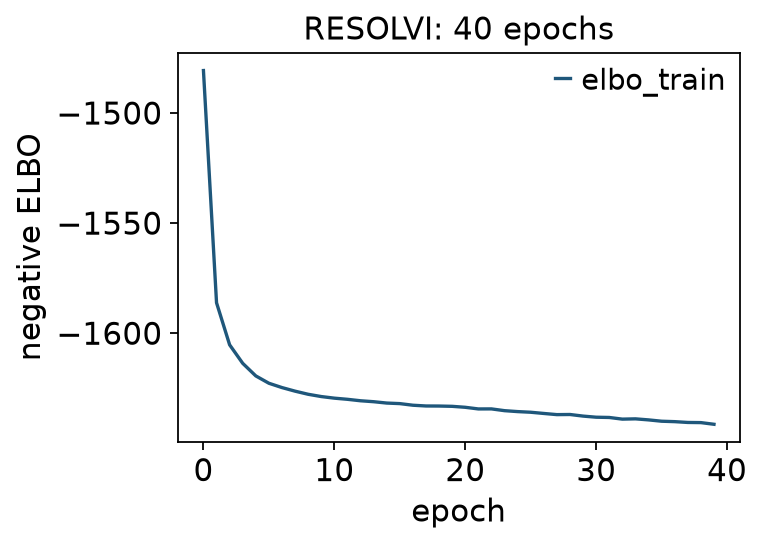

In [10]:
ov.vi.plot_history(model);

The training ELBO drops sharply over the first ~5 epochs (from about -1480 to -1620) and flattens by epoch ~15, settling around -1643 by epoch 40 with no upward turn — consistent with the reference's own convergence behaviour and with 40 epochs not overfitting this 20,000-cell subsample.

### Latent space

`get_latent_representation()` is the posterior mean of `z`. 10x's supervised calls were never shown to this (unsupervised) model — they are only used here to check that the latent space it discovered on its own lines up with an independent annotation.

In [11]:
adata.obsm['X_resolvi'] = model.get_latent_representation()
adata.obsm['X_mde_resolvi'] = ov.vi.mde(adata.obsm['X_resolvi'])

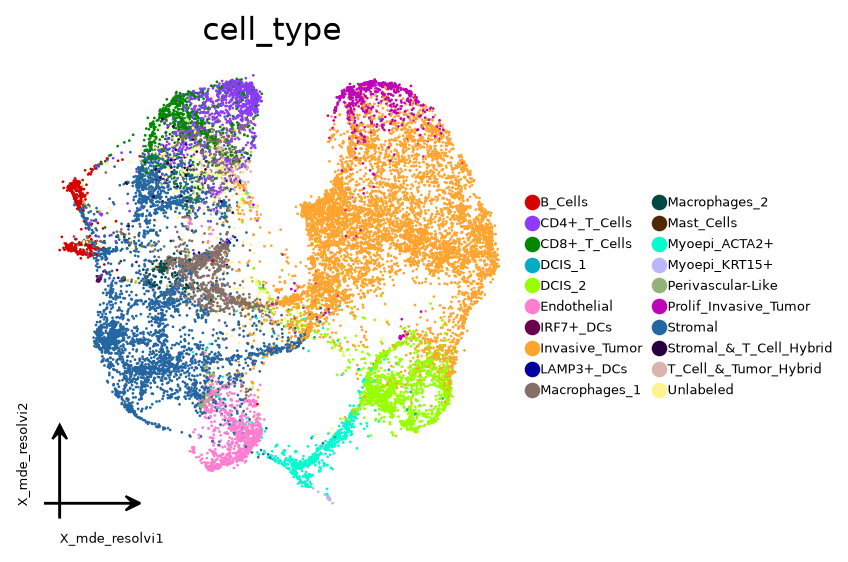

In [12]:
ov.pl.embedding(adata, basis='X_mde_resolvi', color='cell_type', palette=ov.pl.palette_112,
               frameon='small', legend_fontsize=6)

In [13]:
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score
mask = (adata.obs['cell_type'] != 'Unlabeled').values
k = adata.obs['cell_type'][mask].nunique()
pred = KMeans(k, n_init=5, random_state=0).fit_predict(adata.obsm['X_resolvi'][mask])

In [14]:
ari = adjusted_rand_score(adata.obs['cell_type'][mask], pred)
nmi = normalized_mutual_info_score(adata.obs['cell_type'][mask], pred)
print(f'KMeans(k={k}) on the ResolVI latent vs 10x supervised calls: ARI={ari:.3f}  NMI={nmi:.3f}')

KMeans(k=19) on the ResolVI latent vs 10x supervised calls: ARI=0.336  NMI=0.614


ARI=0.336, NMI=0.614 on this 20,000-cell, single-slide tissue-crop subsample — in the same range as the validation benchmark's 8,000-cell random subsample (ARI 0.357 +/- 0.010, NMI 0.627 +/- 0.006 over 3 seeds; `benchmarks/vi/results_resolvi.md` in the omicverse repo), using labels the unsupervised model never saw. Not identical, because the sampling (a real contiguous tissue crop here vs. a random subsample there) and cell count differ, but the magnitude agrees: the 19 non-`Unlabeled` cell types 10x annotated are substantially recovered by plain KMeans on `z` alone.

## 4. Background / diffusion / true proportions on the tissue

`get_proportions()` is the per-cell amortised `(true, diffusion, background)` mixture weight. For Xenium FFPE, the model is expected to assign most mass to `true` + `diffusion` and very little to `background` — imaging-based platforms' dominant noise source is neighbour cross-talk / segmentation error, not an ambient-RNA pool as in droplet scRNA-seq.

In [15]:
props = model.get_proportions()
adata.obs['prop_true'] = props['true'].to_numpy()
adata.obs['prop_diffusion'] = props['diffusion'].to_numpy()
adata.obs['prop_background'] = props['background'].to_numpy()
props.describe()

               true     diffusion    background
count  20000.000000  20000.000000  2.000000e+04
mean       0.812094      0.197905  4.605181e-07
std        0.027704      0.027704  1.170468e-07
min        0.629108      0.078633  1.636584e-07
25%        0.796666      0.182242  3.650168e-07
50%        0.811811      0.198188  4.452943e-07
75%        0.827757      0.213334  5.574744e-07
max        0.931367      0.380891  9.355495e-07

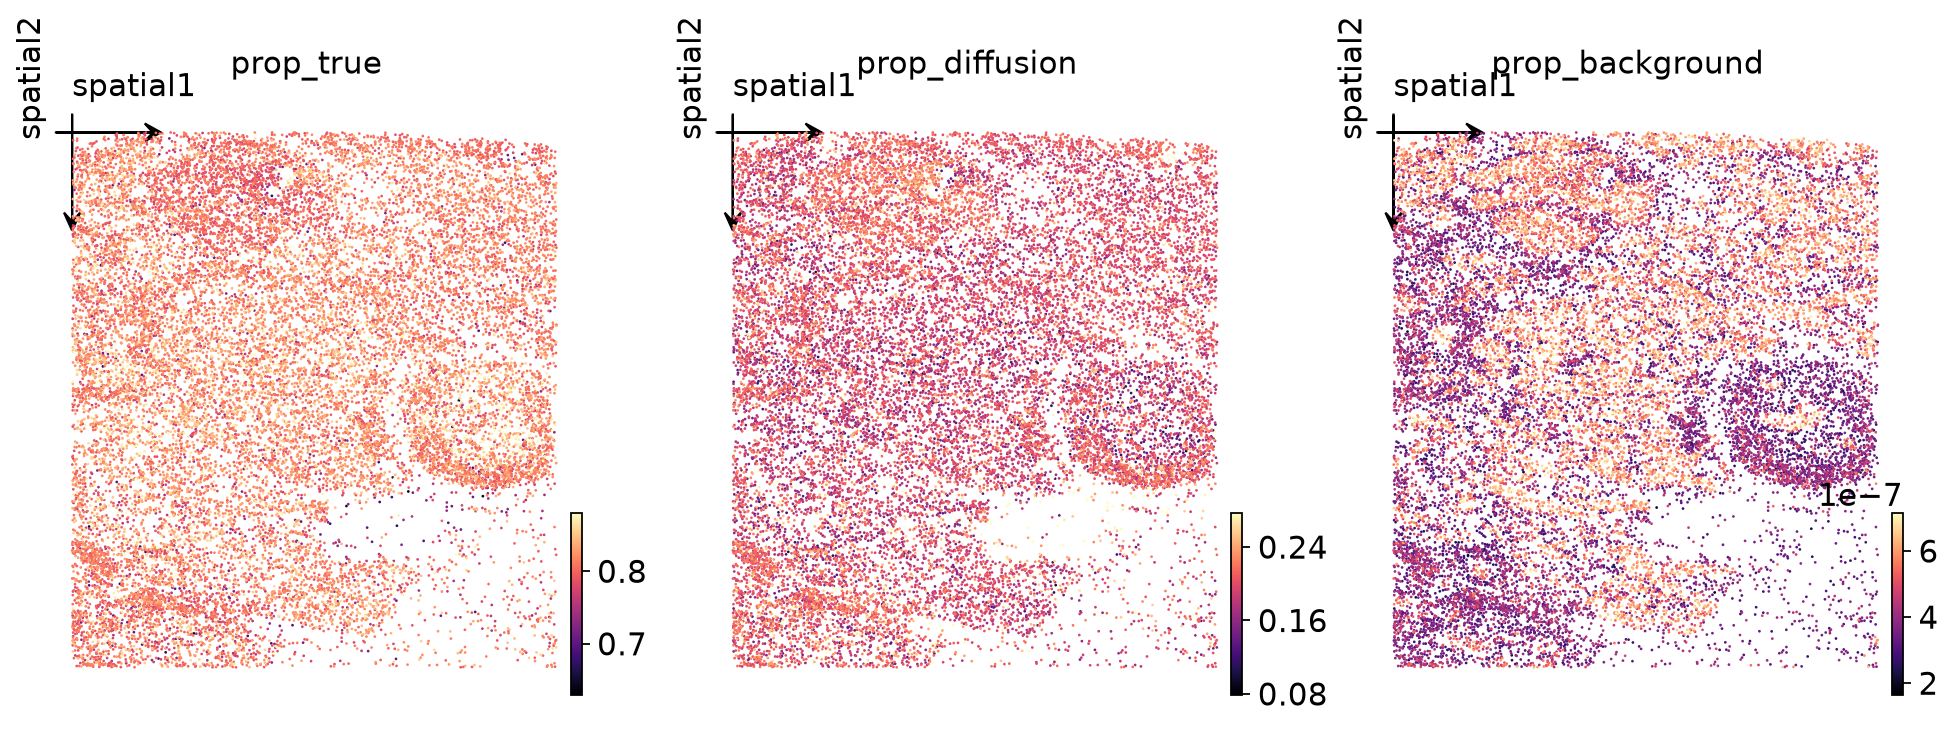

In [16]:
import matplotlib.pyplot as plt
fig, axs = plt.subplots(1, 3, figsize=(15, 5))
for i, col in enumerate(['prop_true', 'prop_diffusion', 'prop_background']):
    ov.pl.embedding(adata, basis='spatial', color=col, cmap='magma', vmax='p99',
                    ax=axs[i], show=False, title=col)
    axs[i].invert_yaxis()

`prop_true` averages 0.812 (+/- 0.028) and is fairly uniform across the tissue; `prop_diffusion` averages 0.198 (+/- 0.028) and is visibly higher around a few duct-like ring structures (most clearly the one on the right of the crop) — plausible, since local cell density and an adjacent lymphocytic cuff (see the `CD3D` / `MS4A1` panels below) change how much of a neighbour's signal spills in. `prop_background` is five to six orders of magnitude smaller (~4.6e-7) and essentially spatially flat — the expected signature for Xenium FFPE, where segmentation / neighbour diffusion, not an ambient-RNA pool, is the dominant noise source (the picture the ResolVI paper reports for imaging-based platforms, unlike droplet scRNA-seq).

## 5. Denoised expression: markers that leak across cell boundaries

`get_normalized_expression(library_size=...)` decodes the posterior mean of `z` into denoised, library-size-normalised "true" expression — the diffusion and background contributions are excluded. We compare it to the matching raw layer for a panel of literature lineage markers (the same 8 used by the validation benchmark), each expected to be specific to one 10x-annotated cell type, and quantify specificity as AUROC of the marker separating its cell type from the rest.

In [17]:
denoised = model.get_normalized_expression(library_size=1e4)
raw = adata[:, denoised.columns].layers['counts']
raw = np.asarray(raw.todense()) if hasattr(raw, 'todense') else np.asarray(raw)
raw = pd.DataFrame(raw, columns=denoised.columns, index=adata.obs_names)

In [18]:
from sklearn.metrics import roc_auc_score
MARKERS = {'KRT8': 'Invasive_Tumor', 'EPCAM': 'Invasive_Tumor', 'PTPRC': 'CD4+_T_Cells',
          'CD3D': 'CD8+_T_Cells', 'CD68': 'Macrophages_1', 'PECAM1': 'Endothelial',
          'MS4A1': 'B_Cells', 'ACTA2': 'Myoepi_ACTA2+'}
rows_auc = [{'gene': g, 'cell_type': ct,
            'auroc_raw': roc_auc_score(adata.obs['cell_type'] == ct, raw[g]),
            'auroc_denoised': roc_auc_score(adata.obs['cell_type'] == ct, denoised[g])}
           for g, ct in MARKERS.items()]
auc_df = pd.DataFrame(rows_auc)
auc_df.round(3)

     gene       cell_type  auroc_raw  auroc_denoised
0    KRT8  Invasive_Tumor      0.825           0.863
1   EPCAM  Invasive_Tumor      0.867           0.948
2   PTPRC    CD4+_T_Cells      0.824           0.956
3    CD3D    CD8+_T_Cells      0.708           0.952
4    CD68   Macrophages_1      0.839           0.979
5  PECAM1     Endothelial      0.945           0.997
6   MS4A1         B_Cells      0.715           0.919
7   ACTA2   Myoepi_ACTA2+      0.793           0.870

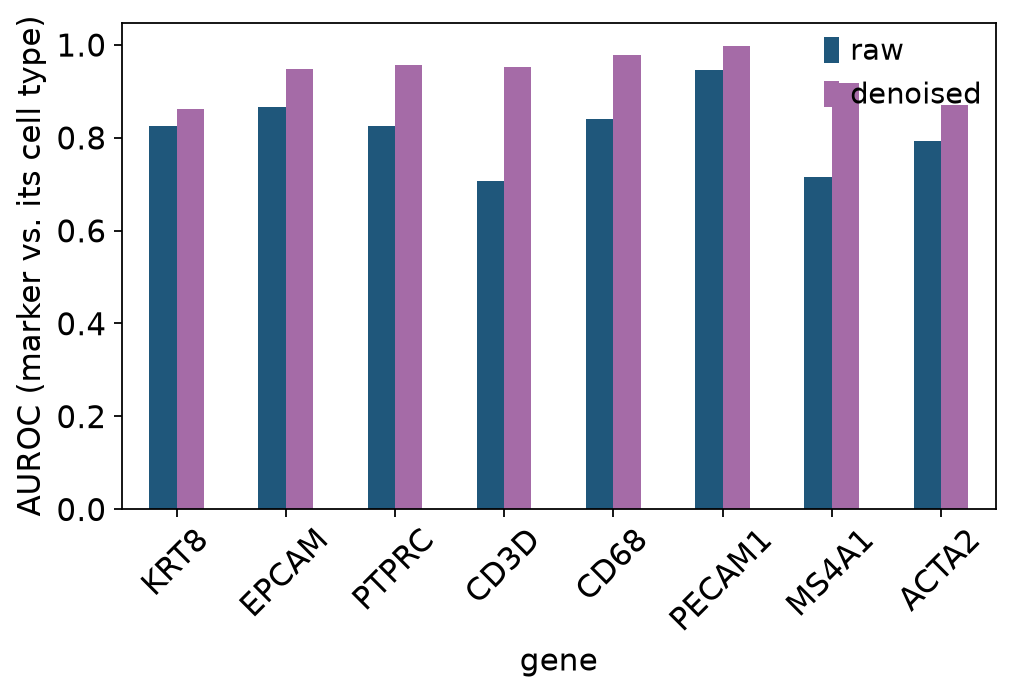

In [19]:
ax = auc_df.set_index('gene')[['auroc_raw', 'auroc_denoised']].plot.bar(figsize=(7, 4), rot=45)
ax.set_ylabel('AUROC (marker vs. its cell type)')
ax.legend(['raw', 'denoised'], frameon=False)

Every marker's AUROC improves after denoising; the two biggest gains are `CD3D` (CD8+ T cells, 0.708 -> 0.952, +0.244) and `MS4A1` (B cells, 0.715 -> 0.919, +0.204) — both lymphocyte markers that are easy to lose in the raw layer, because small, sparse T/B cells sit next to much larger tumour cells and a lot of their transcripts get segmented into the wrong neighbour. The tumour markers `KRT8`/`EPCAM` and the endothelial marker `PECAM1` were already fairly specific raw (AUROC > 0.82) and gain less in absolute terms, consistent with those cell types occupying larger, more homogeneous regions where boundary leakage matters less.

### Before / after on the tissue

The two markers with the largest raw -> denoised AUROC gain, shown as log1p expression on the tissue (same colour scale for raw and denoised).

In [20]:
auc_df['gap'] = auc_df['auroc_denoised'] - auc_df['auroc_raw']
show_genes = auc_df.sort_values('gap', ascending=False)['gene'].head(2).tolist()
for g in show_genes:
    adata.obs[f'{g} (raw)'] = np.log1p(raw[g].to_numpy())
    adata.obs[f'{g} (denoised)'] = np.log1p(denoised[g].to_numpy())

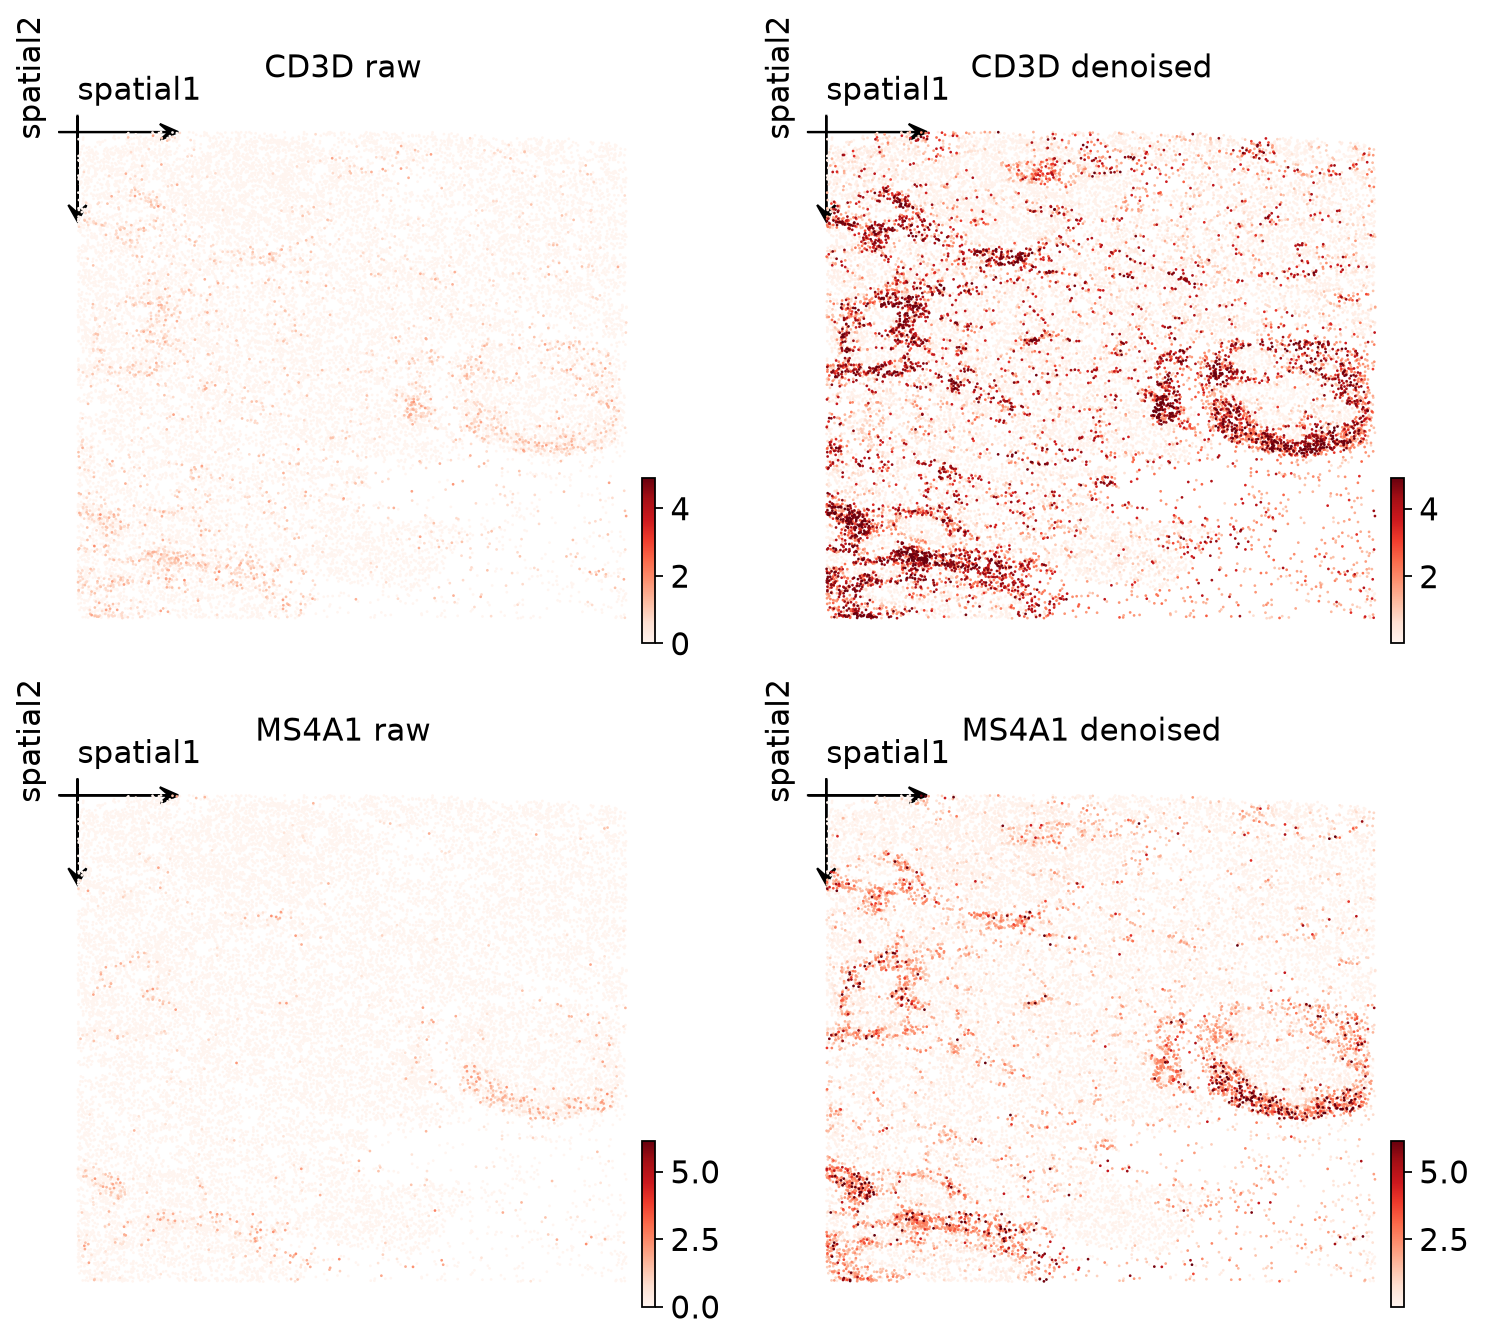

In [21]:
fig, axs = plt.subplots(len(show_genes), 2, figsize=(11, 5 * len(show_genes)))
for j, g in enumerate(show_genes):
    vmax = float(np.percentile(adata.obs[f'{g} (denoised)'], 99))
    ov.pl.embedding(adata, basis='spatial', color=f'{g} (raw)', cmap='Reds', vmax=vmax,
                    ax=axs[j, 0], show=False, title=f'{g} raw')
    ov.pl.embedding(adata, basis='spatial', color=f'{g} (denoised)', cmap='Reds', vmax=vmax,
                    ax=axs[j, 1], show=False, title=f'{g} denoised')
    axs[j, 0].invert_yaxis(); axs[j, 1].invert_yaxis()

In the raw layer, `CD3D` and `MS4A1` are faint and diffuse almost everywhere — expected, since this 313-gene panel yields only a few transcripts per cell for most genes. After denoising, both resolve into sharp, matching ring- and band-shaped structures (most visibly the ring in the lower-right and the band along the bottom of the crop) that read as lymphocytic cuffs around duct-like structures — a hallmark of the tumour microenvironment this sample was collected to characterise (Janesick et al. 2023) — invisible in the raw counts, recovered by pooling each cell's own decoded rate with its spatial neighbours'.

## 6. Semi-supervised ResolVI: predicting hidden cell types

Passing `labels_key` / `unlabeled_category` switches `RESOLVI` to the semi-supervised variant (a classifier head on `z`, one latent-GMM component per label instead of `mixture_k` free components) — exactly as `ov.vi.SCANVI` extends `ov.vi.SCVI`. We hide half of 10x's supervised calls, train on the rest, and ask `predict()` for the hidden half.

In [22]:
truth = adata.obs['cell_type'].astype(str).to_numpy()
hide = (rs.random(len(truth)) < 0.5) & (truth != 'Unlabeled')
adata.obs['label_hidden'] = pd.Categorical(np.where(hide, 'Unknown', truth))
adata.obs['label_hidden'].value_counts().head()

label_hidden
Unknown           9688
Invasive_Tumor    3397
Stromal           1865
DCIS_2             848
Macrophages_1      729
Name: count, dtype: int64

In [23]:
semi = RESOLVI(adata, layer='counts', spatial_key='spatial', labels_key='label_hidden',
              unlabeled_category='Unknown', n_neighbors=10, mixture_k=50,
              n_hidden=32, n_hidden_encoder=128, n_layers=2, dropout_rate=0.05, seed=0)
semi.train(max_epochs=25, device='cuda', batch_size=512, seed=0)

Training:   0%|          | 0/25 [00:00<?, ?epoch/s]

RESOLVI(n_obs=20000, n_vars=313, n_batch=1, n_labels=20, layer='counts', trained=True)

In [24]:
predicted = semi.predict()
acc = (predicted[hide] == truth[hide]).mean()
print(f'semi-supervised accuracy on {hide.sum()} hidden cells: {acc:.3f}')

semi-supervised accuracy on 9688 hidden cells: 0.890


In [25]:
per = pd.DataFrame({'cell_type': truth[hide], 'correct': predicted[hide] == truth[hide]})
per.groupby('cell_type')['correct'].agg(['mean', 'size']).sort_values('size', ascending=False).head(12).round(3)

                        mean  size
cell_type                         
Invasive_Tumor         0.907  3411
Stromal                0.928  1903
DCIS_2                 0.950   825
Macrophages_1          0.888   717
CD4+_T_Cells           0.779   557
Endothelial            0.946   535
CD8+_T_Cells           0.775   454
Prolif_Invasive_Tumor  0.929   393
Myoepi_ACTA2+          0.953   337
B_Cells                0.881   270
Perivascular-Like      0.309    55
Macrophages_2          0.385    52

Overall accuracy on the 9,688 hidden cells is 0.890. Abundant, morphologically distinct types transfer well (`DCIS_2` 0.950, `Myoepi_ACTA2+` 0.953, `Endothelial` 0.946, `Stromal` 0.928, `Invasive_Tumor` 0.907), while CD4+ and CD8+ T cells are confused with each other more often (0.78 each — the two lineages differ by only a few markers on this panel) and the rare, ambiguous `Perivascular-Like` (n=55) and `Macrophages_2` (n=52) categories score worst (0.31, 0.39) — the same informative-rather-than-random error pattern the general `ov.vi` tutorial's SCANVI section finds on a different dataset: errors concentrate on rare or closely related types, not at random.

## 7. Training directly from disk (AnnDataOOM)

`ov.read(path, storage='disk')` returns an **AnnDataOOM**: `obs`/`var` in memory, the count matrix stays on disk. `ov.vi.RESOLVI` streams minibatches from it with the same `pread`-based reader as every other `ov.vi` model — no HDF5 library on the data path, and (as throughout `ov.vi`) **no scvi-tools dependency** at any point.

In [26]:
disk_path = '/scratch/users/steorra/tmp/vi_tut2/resolvi/xenium_resolvi_subsample.h5ad'
adata.write_h5ad(disk_path)
ov.settings.cpu_init()
adata_disk = ov.read(disk_path, storage='disk')
adata_disk

CPU mode activated


📂 Reading with anndata-rs (Rust · out-of-memory)
   /scratch/users/steorra/tmp/vi_tut2/resolvi/xenium_resolvi_subsample.h5ad  (22.6 MB)
   ✓ Loaded in 0.22s

💡 Data stays on disk. Use ov.pp.* for chunked processing.
   adata.close() when done · adata.to_adata() to materialise


name,dtype,preview
transcript_counts,int64,"28, 94, 19, … (714)"
control_probe_counts,int64,"1, 0, 2, … (8)"
control_codeword_counts,int64,"0, 1, 2"
total_counts,int64,"29, 94, 19, … (711)"
cell_area,float64,"58.38703125, 197.01671875, 58.7934375, … (7217)"
nucleus_area,float64,"26.6421875, 42.13078125, 11.06328125, … (3039)"
cell_type,category,"DCIS_2, Macrophages_1, Unlabeled, … (20)"
prop_true,float32,"0.79268605, 0.82126296, 0.80252796, … (19806)"
prop_diffusion,float32,"0.2173133, 0.18873654, 0.20747139, … (19962)"
prop_background,float32,"6.97384e-07, 4.9585697e-07, 6.7123835e-07, … (19984)"


In [27]:
model_disk = RESOLVI(adata_disk, layer='counts', spatial_key='spatial', n_neighbors=10, mixture_k=50,
                     n_hidden=32, n_hidden_encoder=128, n_layers=2, dropout_rate=0.05, seed=0)
model_disk.train(max_epochs=15, device='cuda', batch_size=512, seed=0)

Training:   0%|          | 0/15 [00:00<?, ?epoch/s]

RESOLVI(n_obs=20000, n_vars=313, n_batch=1, n_labels=1, layer='counts', trained=True)

In [28]:
print('in-memory ELBO (40 epochs):', model.get_elbo())
print('disk-backed ELBO (15 epochs):', model_disk.get_elbo())

in-memory ELBO (40 epochs): 1643.184675


disk-backed ELBO (15 epochs): 1632.18135


The disk-backed run (15 epochs) reaches ELBO -1632.18, within 1% of the in-memory run's 40-epoch value (-1643.18) — both on the per-cell scale `ov.vi` reports for `elbo_train`. Given the training curve above already flattens by epoch ~15, this is the expected regime, confirming `ov.vi.RESOLVI` reaches the same objective whether reading `adata.X` resident in memory or streaming row blocks from the `.h5ad` file via `anndata-rs`.

## Key parameters

**Model** (`ov.vi.RESOLVI.__init__`):
- `spatial_key` (`obsm` coordinates), `batch_key` (physical slide; neighbours only searched within a slide), `labels_key` / `unlabeled_category` (semi-supervised variant),
- `n_neighbors` (>= 6, spatial kNN size), `mixture_k` (latent-GMM components, unsupervised only),
- `n_hidden`, `n_hidden_encoder`, `n_latent`, `n_layers`, `dropout_rate` (scvi-tools defaults: 32, 128, 10, 2, 0.05),
- `dispersion` (`'gene'` / `'gene-batch'`), `gene_likelihood` (`'nb'` / `'poisson'`),
- `downsample_counts` (multinomial count-downsampling augmentation, on by default).

**Training** (`model.train`): `max_epochs` (reference default 50), `batch_size` (default 512); `train()` pins the reference's own optimiser defaults internally (`lr=3e-3`, `eps=1e-4`, `weight_decay=0`, `n_epochs_kl_warmup=20`) rather than `ov.vi`'s generic scVI-family defaults — no need to pass them yourself.

**Outputs**: `get_latent_representation()`, `get_proportions()` (`true`/`diffusion`/`background` DataFrame), `get_normalized_expression(library_size=...)` (denoised expression), `get_corrected_counts()` (alias, observed-count scale), `predict()` (semi-supervised models only).

`ov.space.resolvi(adata, layer=..., spatial_key=..., ...)` wraps the same model as a one-call, `adata`-in/`adata`-out function for pipelines (writes the latent embedding, proportions and/or a denoised layer back to `adata`).

## Summary

On a real 20,000-cell crop of the 10x Xenium breast-cancer section, held out of nothing but its own labels: the unsupervised latent recovers 10x's independently-derived cell types it never saw (ARI 0.336, NMI 0.614, in line with the validation benchmark); every one of 8 literature lineage markers becomes more cell-type-specific after denoising (AUROC +0.04 to +0.24, biggest gains for the sparsest lymphocyte markers `CD3D` and `MS4A1`); the per-cell mixture decomposition assigns essentially zero mass to a flat ambient-background channel and the rest to true/diffusion, matching Xenium FFPE's known noise profile; the semi-supervised variant transfers 10x's labels to held-out cells at 89.0% accuracy with errors concentrated on closely related or rare types; and training from an on-disk AnnDataOOM reaches the same ELBO as training in memory. Known simplifications not exercised here (per the model's docstring): `size_scaling` and `differential_expression` / `differential_niche_abundance` are not ported, and `cuda_graph` / `torch.compile` are disabled for this model (both strip the per-cell row index that `RESOLVI` needs to index `per_neighbor_diffusion_map`).

## Related tutorials

- [t_xenium_preprocess](../Tutorials-space/t_xenium_preprocess.ipynb) — reading, QC, clustering and segmentation-polygon visualization of the same platform.
- [t_vi](../Tutorials-single/batch/t_vi.ipynb) — the general `ov.vi` walkthrough (in-memory / AnnDataOOM / Dask / multi-GPU, `SCVI`/`SCANVI`/`TOTALVI`) that this notebook's disk-backed section follows.